# Caron & Fox: Sparse Graphs from Exchangeable Random Measures

A short tour of the generative construction from:

>Caron, F. and Fox, E.B. (2017), Sparse graphs using exchangeable random measures. J. R. Stat. Soc. B, 79: 1295-1366. https://doi.org/10.1111/rssb.12233.


All of the code below is a direct port of Francois Caron's MATLAB `BNPgraph` package, in `Caron_Fox_BNPGraph.py` in the src folder (Colab downloads it automatically).

In [ ]:
import sys

# On Colab: install igraph and download Caron_Fox_BNPGraph.py. Locally: read it from ../src.
if "google.colab" in sys.modules:
    !pip install -q python-igraph
    BASE = "https://raw.githubusercontent.com/sevvandi/sevvandi.github.io/BRANCH/assets/notebooks/NeurIPS_2026/src"
    !wget -q {BASE}/Caron_Fox_BNPGraph.py
else:
    sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
import igraph as ig
import warnings
import importlib

from Caron_Fox_BNPGraph import (
    ggp_rnd,
    ggp_graphrnd,
    ggp_bipgraphrnd,
    ggp_sumrnd,
    plot_degree,
    sample_graph_with_n_nodes,
)

# The rejection samplers underlying the GGP construction can trigger benign
# overflow warnings deep in the tilted-stable sampler (values saturate to
# inf and get rejected, as intended) -- suppress those for a clean notebook.
warnings.filterwarnings("ignore", category=RuntimeWarning)

%matplotlib inline
rng = np.random.default_rng(0)

## Example 1: Generating a graph

alpha=6.594: 109 nodes, 220 edges


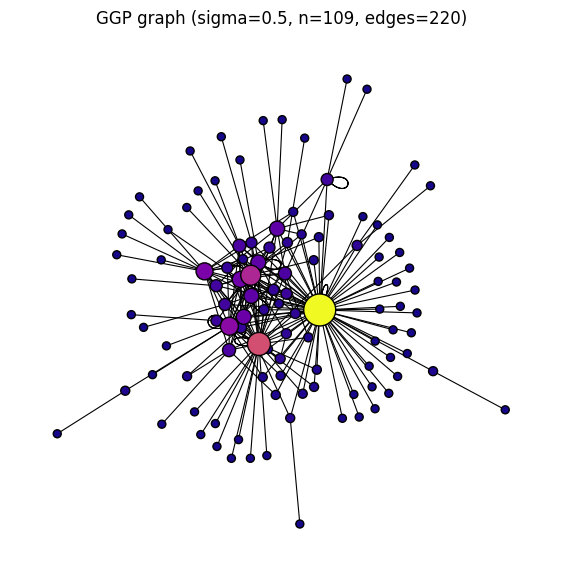

In [3]:
rng = np.random.default_rng(0)
G, w, w_rem, alpha, sigma, tau = sample_graph_with_n_nodes(100, sigma=0.5, tau=1e-4, rng=rng)

n = G.shape[0]
n_edges = G.nnz // 2
print(f"alpha={alpha:.3f}: {n} nodes, {n_edges} edges")


g = ig.Graph.Adjacency((G.toarray() > 0).tolist(), mode="undirected")
deg = np.array(g.degree())

sizes = 6 + 26 * (deg / deg.max()) ** 0.6
cmap = plt.get_cmap("plasma")
colors = [cmap(d) for d in deg / deg.max()]

fig, ax = plt.subplots(figsize=(7, 7))
layout = g.layout("fr")
ig.plot(g, target=ax, layout=layout, vertex_size=sizes, vertex_color=colors,
        edge_color=(0.7, 0.7, 0.7, 0.6), edge_width=0.8)
ax.set_title(f"GGP graph (sigma={sigma}, n={n}, edges={n_edges})")
plt.show()


## Example 2: A graph from a sparse sequence

We sample a graph with $\sigma = 0.5$ and look at both the adjacency matrix and the degree distribution.

In [4]:
alpha, sigma, tau = 10, 0.7, 1e-2
T = 1e-6  # truncation threshold for the underlying Levy process

G, w, w_rem, alpha, sigma, tau = ggp_graphrnd(alpha, sigma, tau, T, rng=rng)

n = G.shape[0]
n_edges = G.nnz // 2
print(f"sigma={sigma}: {n} nodes, {n_edges} edges")
print(f"mean degree: {G.sum() / n:.2f}   max degree: {np.asarray(G.sum(axis=0)).max():.0f}")


sigma=0.7: 196 nodes, 245 edges
mean degree: 2.50   max degree: 105


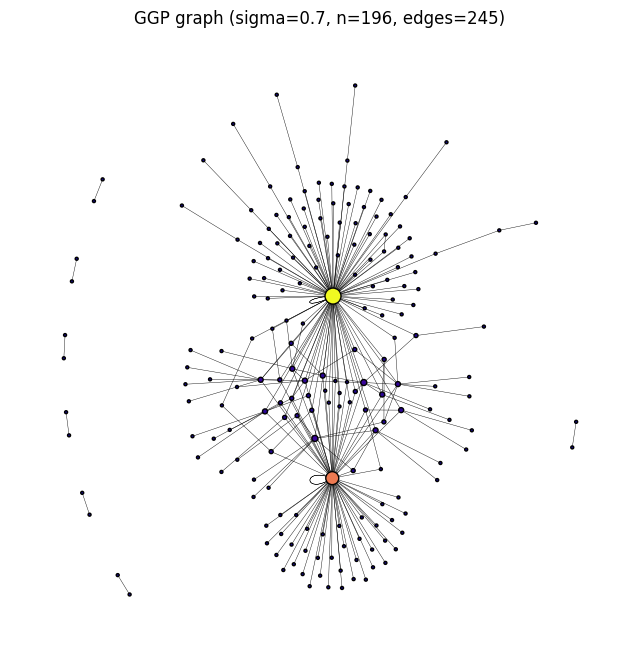

In [5]:
g = ig.Graph.Adjacency((G.toarray() > 0).tolist(), mode="undirected")
deg = np.array(g.degree())

# size and color scale with degree, so hubs pop out without dominating the layout
sizes = 2 + 14 * (deg / deg.max()) ** 0.5
cmap = plt.get_cmap("plasma")
colors = [cmap(d) for d in deg / deg.max()]

fig, ax = plt.subplots(figsize=(8, 8))
layout = g.layout("fr")
ig.plot(
    g,
    target=ax,
    layout=layout,
    vertex_size=sizes,
    vertex_color=colors,
    edge_width=0.3,
    edge_color=(0.6, 0.6, 0.6, 0.4),
)
ax.set_title(f"GGP graph (sigma={sigma}, n={n}, edges={n_edges})")
plt.show()

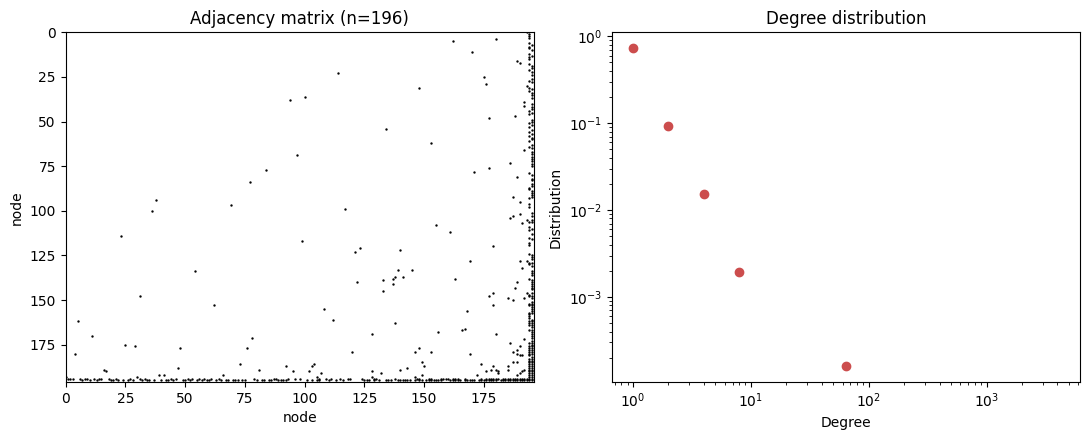

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Adjacency matrix (spy plot)
rows, cols = G.nonzero()
axes[0].scatter(cols, rows, s=0.5, color="black")
axes[0].set_xlim(0, n)
axes[0].set_ylim(n, 0)
axes[0].set_title(f"Adjacency matrix (n={n})")
axes[0].set_xlabel("node")
axes[0].set_ylabel("node")

# Degree distribution, log-log with logarithmic binning
plot_degree(G, ax=axes[1], linespec="o", color=(0.8, 0.3, 0.3))
axes[1].set_title("Degree distribution")

plt.tight_layout()
plt.show()

Notice the roughly straight-line decay on the log-log degree plot -- a signature of a **power-law** degree distribution, and a few very high-degree hub nodes. This is exactly the sparse, heavy-tailed structure real-world networks tend to show, and it's the main phenomenon the GGP construction is built to reproduce.

## Example 3: Dense vs. sparse -- the role of $\sigma$

Now we compare three values of $\sigma$ at (roughly) matched scale:
- $\sigma = -1$ (finite-activity GGP -- a **dense**, Erdos-Renyi-like graph)
- $\sigma = 0$ (gamma process)
- $\sigma = 0.7$ (**sparse**, strongly power-law)

For each, we sample a graph and look at how the number of edges grows with the number of nodes, and the resulting degree distributions side by side.

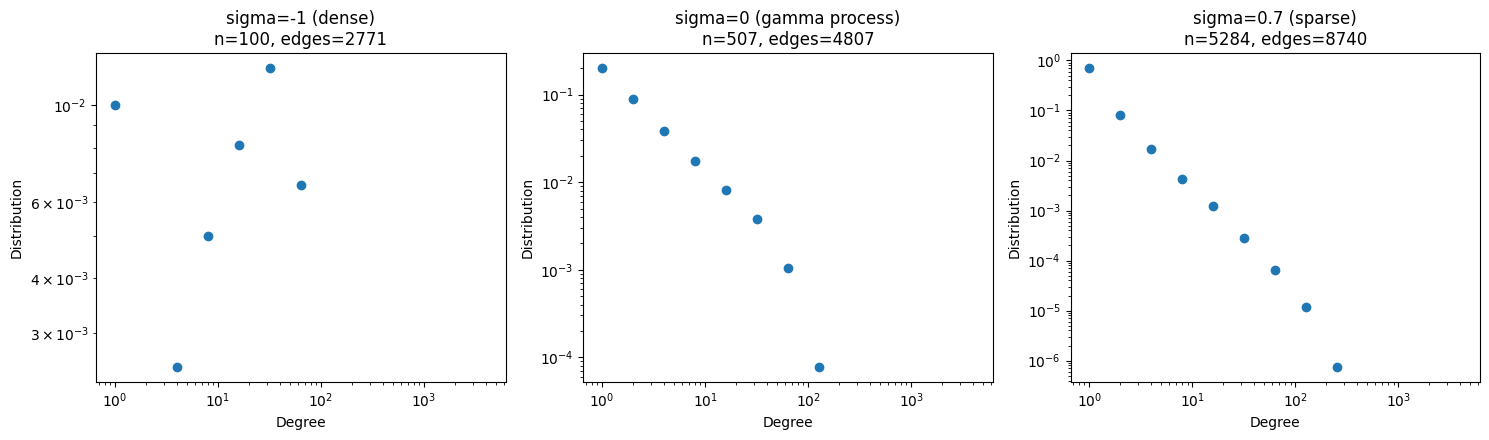

In [7]:
sigmas = [-1.0, 0.0, 0.7]
labels = ["sigma=-1 (dense)", "sigma=0 (gamma process)", "sigma=0.7 (sparse)"]
alpha = 100
tau = 1.0  # tau>0 needed for sigma<=0

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for sigma, label, ax in zip(sigmas, labels, axes):
    Gs, ws, w_rem_s, *_ = ggp_graphrnd(alpha, sigma, tau, 1e-6, rng=rng)
    n_s = Gs.shape[0]
    e_s = Gs.nnz // 2
    plot_degree(Gs, ax=ax, linespec="o")
    ax.set_title(f"{label}\nn={n_s}, edges={e_s}")

plt.tight_layout()
plt.show()

As $\sigma$ increases from negative towards 1, the degree distribution develops a heavier and heavier tail (more visible straight-line decay on the log-log plot), and the graph becomes sparser relative to its node count -- fewer edges are needed per node to reach the same overall scale $\alpha$. 

## Note

The package's posterior-inference (MCMC) layer is not included here -- only the generative construction.